Conteos por fecha y treatment_floor:

--- Fecha 20260608 ---
treatment_floor
1    3
2    3
3    3
4    3
5    3
6    3
7    3
8    3
9    3
Name: count, dtype: int64

--- Fecha 20260331 ---
treatment_floor
1    3
2    3
3    3
4    3
5    3
6    3
7    3
8    3
9    3
Name: count, dtype: int64

--- Fecha 20260622 ---
treatment_floor
1    3
2    3
3    3
4    3
5    3
6    3
7    3
8    3
9    3
Name: count, dtype: int64
----------------------------------------


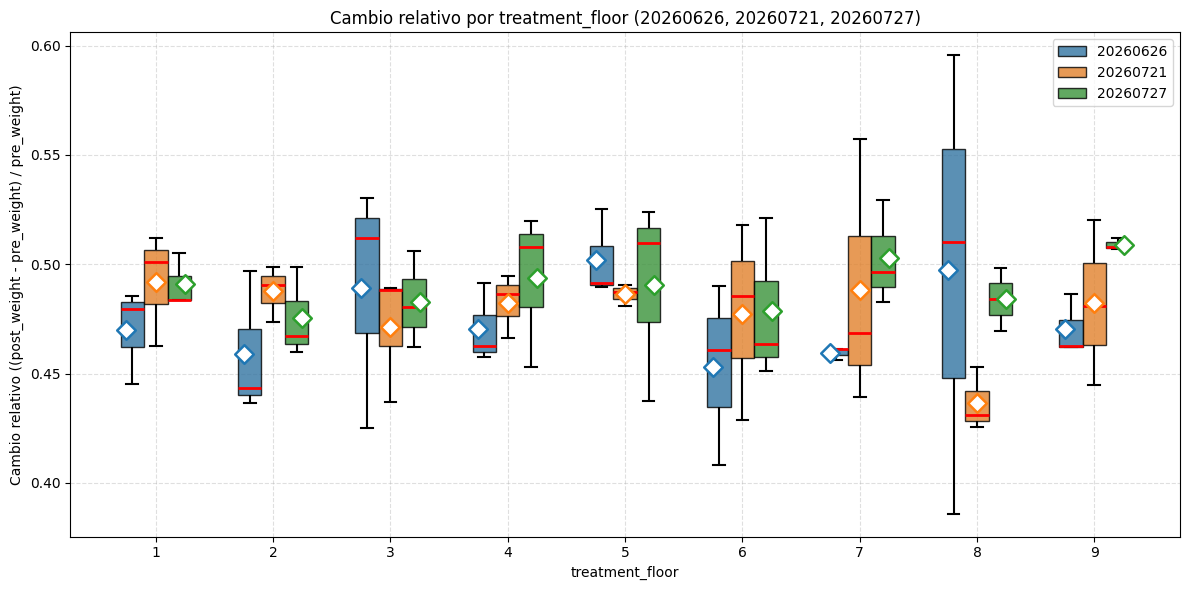

In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### CERAMICA
#fechas = ["20260608", "20260331", "20260622"]

### NEODIMIO
fechas = ["20260626", "20260721", "20260727"]

experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")

print("Conteos por fecha y treatment_floor:")
for f in ["20260608", "20260331", "20260622"]:
    p = experiments_dir / f / "trays.csv"
    if p.exists():
        temp_df = pd.read_csv(p)
        print(f"\n--- Fecha {f} ---")
        # Cuenta cuántos hay por cada piso y los ordena por el número de piso
        print(temp_df["treatment_floor"].value_counts().sort_index())
    else:
        print(f"\nFecha {f}: Archivo no encontrado")
print("-" * 40)

def cargar_trays(fecha, grupo_grafica):
    trays_path = experiments_dir / fecha / "trays.csv"
    if not trays_path.exists():
        raise FileNotFoundError(f"No se encontro {trays_path}")

    fecha_df = pd.read_csv(trays_path)
    fecha_df["fecha"] = fecha
    fecha_df["grupo_grafica"] = grupo_grafica
    return fecha_df

dfs = []
for fecha in fechas:
    dfs.append(cargar_trays(fecha, fecha))

df = pd.concat(dfs, ignore_index=True)
df["treatment_floor"] = pd.to_numeric(df["treatment_floor"], errors="coerce")
df["pct_change"] = (df["post_weight"] - df["pre_weight"]) / df["pre_weight"]
control_floor = 9

grupo_order = list(fechas)
floor_order = sorted(df["treatment_floor"].dropna().unique())
palette = dict(zip(grupo_order, sns.color_palette("tab10", n_colors=len(grupo_order))))
titulo_grupos = ", ".join(fechas)

plt.figure(figsize=(12, 6))
# Boxplot por treatment_floor y fecha
sns.boxplot(
    data=df,
    x="treatment_floor",
    y="pct_change",
    hue="grupo_grafica",
    order=floor_order,
    hue_order=grupo_order,
    palette=palette,
    width=0.6,
    medianprops={"color": "red", "linewidth": 2},
    whiskerprops={"color": "k", "linewidth": 1.5},
    capprops={"color": "k", "linewidth": 1.5},
    boxprops={"alpha": 0.8, "edgecolor": "k"}
)

# Media por treatment_floor y fecha como rombo blanco
mean_df = df.groupby(["treatment_floor", "grupo_grafica"], as_index=False)["pct_change"].mean()
offsets = {grupo: 0 for grupo in grupo_order}
if len(grupo_order) > 1:
    offsets = {grupo: -0.25 + i * (0.5 / (len(grupo_order) - 1)) for i, grupo in enumerate(grupo_order)}

for grupo in grupo_order:
    grupo_means = mean_df[mean_df["grupo_grafica"] == grupo]
    x_positions = [floor_order.index(floor) + offsets[grupo] for floor in grupo_means["treatment_floor"]]
    plt.scatter(
        x_positions,
        grupo_means["pct_change"],
        marker="D",
        s=90,
        facecolors="white",
        edgecolors=palette[grupo],
        linewidths=1.8,
        zorder=10,
    )

plt.xlabel("treatment_floor")
plt.ylabel("Cambio relativo ((post_weight - pre_weight) / pre_weight)")
plt.title(f"Cambio relativo por treatment_floor ({titulo_grupos})")
plt.xticks(range(len(floor_order)), floor_order)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

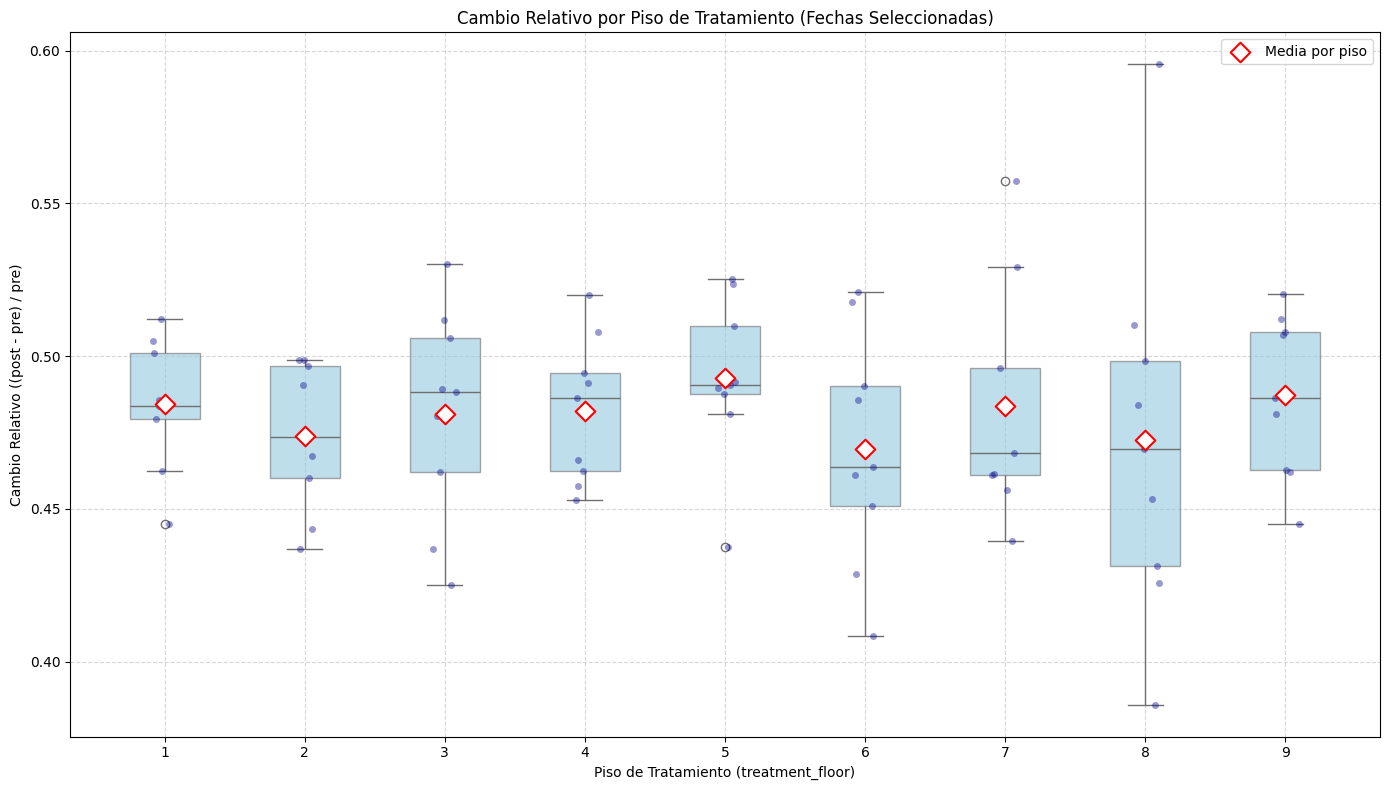

In [2]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")

#### GRAFICA DE COMPARATIVA DE EXPERIMENTO
# Usa las fechas definidas en la primera celda
fechas_validas = fechas

all_dfs = []
for fecha in fechas_validas:
    trays_path = experiments_dir / fecha / "trays.csv"
    if trays_path.exists():
        df = pd.read_csv(trays_path)
        df['fecha'] = fecha
        all_dfs.append(df)
    else:
        print(f"Advertencia: No se encontró el archivo para la fecha {fecha}")

if all_dfs:
    combined_df = pd.concat(all_dfs, ignore_index=True)
    combined_df["treatment_floor"] = pd.to_numeric(combined_df["treatment_floor"], errors="coerce")
    combined_df = combined_df.dropna(subset=['treatment_floor'])
    combined_df["pct_change"] = (combined_df["post_weight"] - combined_df["pre_weight"]) / combined_df["pre_weight"]

    floor_order = sorted(combined_df["treatment_floor"].unique())

    plt.figure(figsize=(14, 8))

    # Boxplot para ver la distribución completa
    sns.boxplot(
        data=combined_df,
        x="treatment_floor",
        y="pct_change",
        order=floor_order,
        color="skyblue",
        width=0.5,
        boxprops={'alpha':0.6}
    )

    # Stripplot para ver los puntos individuales
    sns.stripplot(
        data=combined_df,
        x='treatment_floor',
        y='pct_change',
        order=floor_order,
        color='darkblue',
        alpha=0.4,
        jitter=True
    )
    
    # Marcador para la media de cada grupo
    mean_df = combined_df.groupby("treatment_floor")["pct_change"].mean().reset_index()
    
    # Mapear los valores de x a los índices para el scatter plot
    x_positions = {floor: i for i, floor in enumerate(floor_order)}
    mean_df['x_pos'] = mean_df['treatment_floor'].map(x_positions)
    
    plt.scatter(
        x=mean_df['x_pos'],
        y=mean_df['pct_change'],
        marker='D',
        s=100,
        facecolors='white',
        edgecolors='red',
        linewidths=1.5,
        zorder=10,
        label='Media por piso'
    )

    plt.xlabel("Piso de Tratamiento (treatment_floor)")
    plt.ylabel("Cambio Relativo ((post - pre) / pre)")
    plt.title("Cambio Relativo por Piso de Tratamiento (Fechas Seleccionadas)")
    plt.xticks(ticks=range(len(floor_order)), labels=floor_order)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron datos de experimentos para las fechas indicadas.")

In [3]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

import scipy.stats as stats

# FIX: Use combined_df from the previous cell which contains ALL experiment data,
# preventing issues from other cells filtering the global 'df'.
control_floor = 9 # Ensure control_floor is defined
df_floor = combined_df[combined_df["treatment_floor"].isin(range(1, control_floor + 1))].copy()

# Ensure 'pct_change' is calculated if it wasn't already on combined_df
if 'pct_change' not in df_floor.columns:
    df_floor["pct_change"] = (df_floor["post_weight"] - df_floor["pre_weight"]) / df_floor["pre_weight"]

df_floor = df_floor.dropna(subset=["pct_change", "treatment_floor"])
df_floor["treatment_floor"] = df_floor["treatment_floor"].astype(int)

print("Verificación de datos en el DataFrame combinado:")
print(df_floor[["treatment_floor", "floor"]].value_counts().sort_index())

print("Resumen por treatment_floor:")
print(df_floor.groupby("treatment_floor")["pct_change"].agg(["count", "mean", "std"]))
print()

modelo_floor = ols("pct_change ~ C(treatment_floor)", data=df_floor).fit()
anova_result = anova_lm(modelo_floor, typ=2)
print("ANOVA unidireccional para treatment_floor:")
print(anova_result)
print()

tukey = pairwise_tukeyhsd(df_floor["pct_change"], df_floor["treatment_floor"], alpha=0.05)
tukey_df = pd.DataFrame(tukey._results_table.data[1:], columns=tukey._results_table.data[0])
print("Comparaciones múltiples con Tukey HSD:")
print(tukey_df)
print()

control_pairs = tukey_df[
    (tukey_df["group1"] == control_floor) | (tukey_df["group2"] == control_floor)
]
print("Comparaciones Tukey HSD vs control floor 9:")
print(control_pairs)
print()

control_vals = df_floor.loc[df_floor["treatment_floor"] == control_floor, "pct_change"]
pairwise_results = []
for floor in range(1, control_floor):
    floor_vals = df_floor.loc[df_floor["treatment_floor"] == floor, "pct_change"]
    t_stat, p_val = stats.ttest_ind(floor_vals, control_vals, equal_var=False, nan_policy="omit")
    pairwise_results.append({"floor": floor, "t_stat": t_stat, "p_val": p_val})

p_vals = [x["p_val"] for x in pairwise_results]
# Filter out nan p-values before passing to multipletests
valid_indices = [i for i, p in enumerate(p_vals) if not pd.isna(p)]
p_vals_to_test = [p for p in p_vals if not pd.isna(p)]

if p_vals_to_test:
    _, p_adj, _, _ = multipletests(p_vals_to_test, method="holm")
    p_adj_full = [None] * len(p_vals)
    for i, adj_p in zip(valid_indices, p_adj):
        p_adj_full[i] = adj_p
else:
    p_adj_full = [None] * len(p_vals)


print("Pruebas por pares (tratamiento vs control floor 9) con corrección Holm:")
for i, (res, padj) in enumerate(zip(pairwise_results, p_adj_full)):
    # Check if there was data to compare
    if pd.isna(res['p_val']):
        print(f"floor {res['floor']} vs {control_floor}: No data for comparison or control is empty")
    else:
        print(
            f"floor {res['floor']} vs {control_floor}: "
            f"t={res['t_stat']:.4f}, p={res['p_val']:.4e}, p_holm={padj:.4e}"
        )

Verificación de datos en el DataFrame combinado:
treatment_floor  floor
1                A        3
                 B        3
                 C        3
2                A        3
                 B        3
                 C        3
3                A        3
                 B        3
                 C        3
4                A        3
                 B        3
                 C        3
5                A        3
                 B        3
                 C        3
6                A        3
                 B        3
                 C        3
7                A        3
                 B        3
                 C        3
8                A        3
                 B        3
                 C        3
9                A        3
                 B        3
                 C        3
Name: count, dtype: int64
Resumen por treatment_floor:
                 count      mean       std
treatment_floor                           
1                    9  0.48427

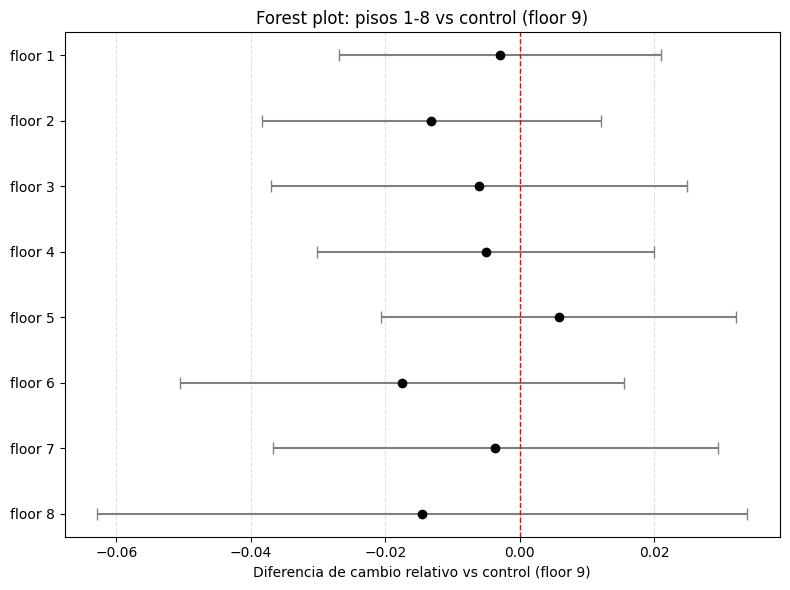

In [4]:
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW
import matplotlib.pyplot as plt

# Forest plot: diferencia de medias (pct_change) de cada piso vs el control (floor 9),
# con IC 95% (Welch, mismo supuesto que el t-test por pares de arriba)
control_vals = df_floor.loc[df_floor["treatment_floor"] == control_floor, "pct_change"]

forest_rows = []
for floor in range(1, control_floor):
    floor_vals = df_floor.loc[df_floor["treatment_floor"] == floor, "pct_change"]
    cm = CompareMeans(DescrStatsW(floor_vals), DescrStatsW(control_vals))
    diff = floor_vals.mean() - control_vals.mean()
    ci_low, ci_high = cm.tconfint_diff(alpha=0.05, usevar="unequal")
    forest_rows.append({"floor": floor, "diff": diff, "ci_low": ci_low, "ci_high": ci_high})

forest_df = pd.DataFrame(forest_rows)

plt.figure(figsize=(8, 6))
plt.errorbar(
    forest_df["diff"],
    forest_df["floor"],
    xerr=[forest_df["diff"] - forest_df["ci_low"], forest_df["ci_high"] - forest_df["diff"]],
    fmt="o",
    color="black",
    ecolor="gray",
    elinewidth=1.5,
    capsize=4,
    markersize=6,
)
plt.axvline(0, color="red", linestyle="--", linewidth=1)
plt.yticks(forest_df["floor"], [f"floor {f}" for f in forest_df["floor"]])
plt.gca().invert_yaxis()
plt.xlabel(f"Diferencia de cambio relativo vs control (floor {control_floor})")
plt.title("Forest plot: pisos 1-8 vs control (floor 9)")
plt.grid(True, axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Success: test_output.png generated.


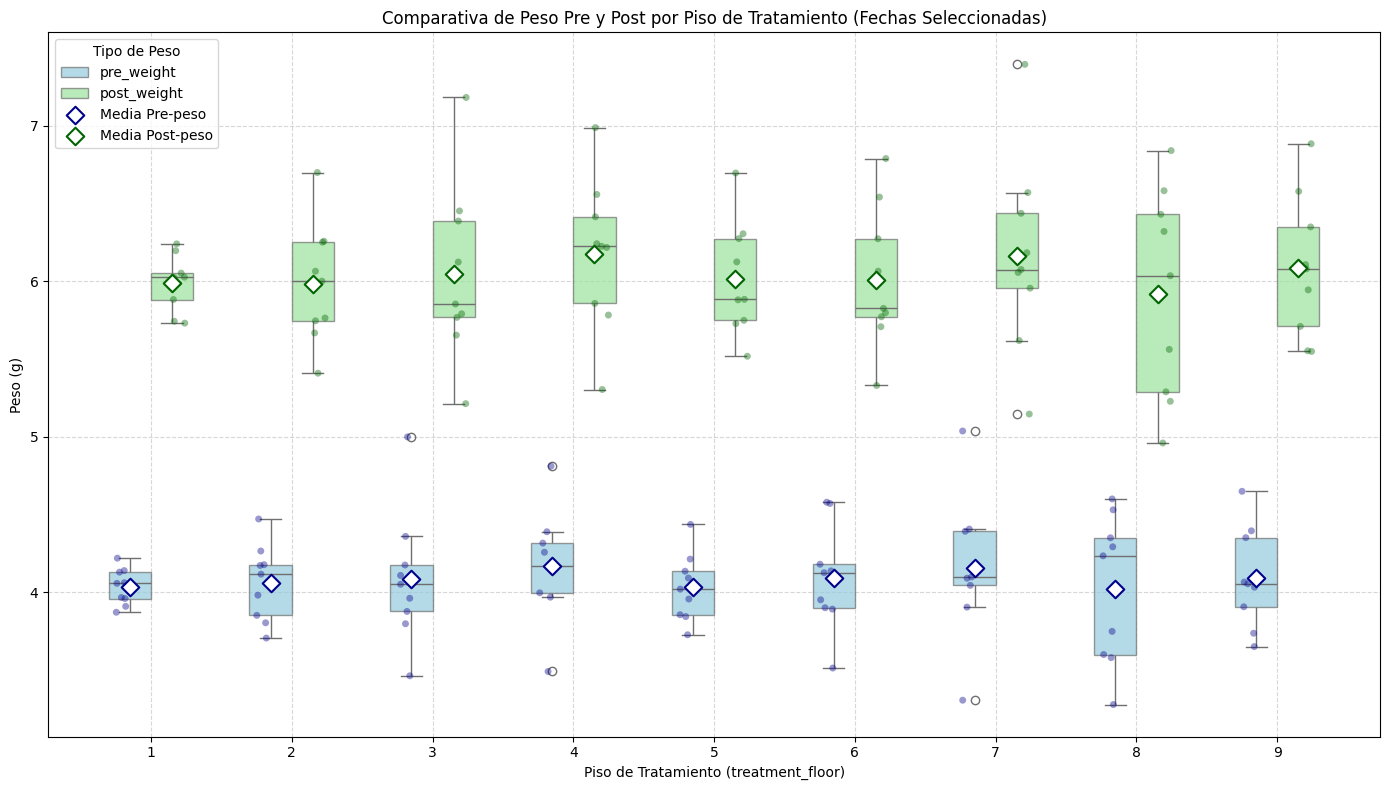

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")

# Usa las fechas definidas en la primera celda
fechas_validas = fechas

all_dfs = []
for fecha in fechas_validas:
    trays_path = experiments_dir / fecha / "trays.csv"
    if trays_path.exists():
        df = pd.read_csv(trays_path)
        df['fecha'] = fecha
        all_dfs.append(df)
    else:
        print(f"Advertencia: No se encontró el archivo para la fecha {fecha}")

if all_dfs:
    combined_df = pd.concat(all_dfs, ignore_index=True)
    combined_df["treatment_floor"] = pd.to_numeric(combined_df["treatment_floor"], errors="coerce")
    combined_df = combined_df.dropna(subset=['treatment_floor'])

    # Reestructurar el DataFrame a formato largo para graficar pre y post weight en el eje y
    df_melted = pd.melt(
        combined_df,
        id_vars=["treatment_floor"],
        value_vars=["pre_weight", "post_weight"],
        var_name="Tipo de Peso",
        value_name="Peso"
    )
    df_melted["treatment_floor"] = df_melted["treatment_floor"].astype(int)
    floor_order = sorted(df_melted["treatment_floor"].unique())

    plt.figure(figsize=(14, 8))

    # Boxplot para ver la distribución de pre y post weight por piso
    sns.boxplot(
        data=df_melted,
        x="treatment_floor",
        y="Peso",
        hue="Tipo de Peso",
        order=floor_order,
        palette={"pre_weight": "skyblue", "post_weight": "lightgreen"},
        width=0.6,
        boxprops={'alpha':0.7}
    )

    # Stripplot para ver los puntos individuales
    sns.stripplot(
        data=df_melted,
        x="treatment_floor",
        y="Peso",
        hue="Tipo de Peso",
        order=floor_order,
        palette={"pre_weight": "darkblue", "post_weight": "darkgreen"},
        dodge=True,
        alpha=0.4,
        jitter=True,
        legend=False
    )

    # Marcador para la media de cada grupo
    mean_df = df_melted.groupby(["treatment_floor", "Tipo de Peso"])["Peso"].mean().reset_index()
    
    # Mapear los valores de x a los índices para el scatter plot
    x_positions = {floor: i for i, floor in enumerate(floor_order)}
    mean_df['x_pos'] = mean_df['treatment_floor'].map(x_positions).astype(float)
    
    # Ajustar las posiciones x según la categoría (dodge) para alinear con los boxplots
    mean_df.loc[mean_df["Tipo de Peso"] == "pre_weight", "x_pos"] -= 0.15
    mean_df.loc[mean_df["Tipo de Peso"] == "post_weight", "x_pos"] += 0.15
    
    plt.scatter(
        x=mean_df[mean_df["Tipo de Peso"] == "pre_weight"]['x_pos'],
        y=mean_df[mean_df["Tipo de Peso"] == "pre_weight"]['Peso'],
        marker='D',
        s=80,
        facecolors='white',
        edgecolors='darkblue',
        linewidths=1.5,
        zorder=10,
        label='Media Pre-peso'
    )
    plt.scatter(
        x=mean_df[mean_df["Tipo de Peso"] == "post_weight"]['x_pos'],
        y=mean_df[mean_df["Tipo de Peso"] == "post_weight"]['Peso'],
        marker='D',
        s=80,
        facecolors='white',
        edgecolors='darkgreen',
        linewidths=1.5,
        zorder=10,
        label='Media Post-peso'
    )

    plt.xlabel("Piso de Tratamiento (treatment_floor)")
    plt.ylabel("Peso (g)")
    plt.title("Comparativa de Peso Pre y Post por Piso de Tratamiento (Fechas Seleccionadas)")
    plt.xticks(ticks=range(len(floor_order)), labels=floor_order)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(title="Tipo de Peso")
    plt.tight_layout()
    plt.savefig("test_output.png")
    print("Success: test_output.png generated.")
else:
    print("No se encontraron datos.")


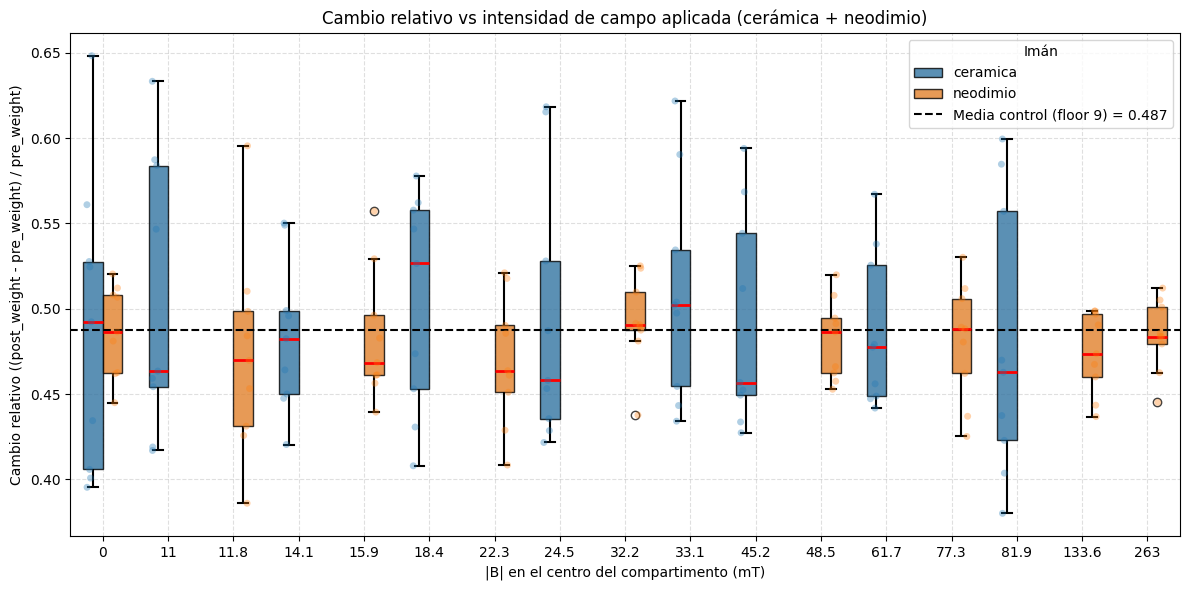

In [6]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Todas las variables de esta celda usan el prefijo campo_ para no chocar
# con df/combined_df/fechas ya usados en celdas anteriores.
campo_experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")
campo_extra_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/extra")

campo_fechas_por_iman = {
    "ceramica": ["20260608", "20260331", "20260622"],
    "neodimio": ["20260626", "20260721", "20260727"],
}
campo_control_floor = 9

campo_b_compart = {
    "ceramica": pd.read_csv(campo_extra_dir / "dosis_ceramica_compart.csv"),
    "neodimio": pd.read_csv(campo_extra_dir / "dosis_neodimio_compart.csv"),
}

campo_dfs = []
for iman, fechas_iman in campo_fechas_por_iman.items():
    b_iman = campo_b_compart[iman].copy()
    for fecha in fechas_iman:
        trays_path = campo_experiments_dir / fecha / "trays.csv"
        if not trays_path.exists():
            print(f"Advertencia: no se encontro {trays_path}")
            continue
        fecha_df = pd.read_csv(trays_path)
        fecha_df["iman"] = iman
        fecha_df["fecha"] = fecha
        campo_dfs.append(fecha_df)

campo_df = pd.concat(campo_dfs, ignore_index=True)
campo_df["treatment_floor"] = pd.to_numeric(campo_df["treatment_floor"], errors="coerce")
campo_df = campo_df.dropna(subset=["treatment_floor"])
campo_df["treatment_floor"] = campo_df["treatment_floor"].astype(int)
campo_df["pct_change"] = (campo_df["post_weight"] - campo_df["pre_weight"]) / campo_df["pre_weight"]

# Asigna B_compart_mT segun el imán y el nivel; el control (floor 9) no tiene
# fila en las tablas de dosis porque no recibe campo aplicado -> B = 0.
campo_b_lookup = pd.concat(
    [b_iman.assign(iman=iman) for iman, b_iman in campo_b_compart.items()],
    ignore_index=True,
).rename(columns={"nivel": "treatment_floor"})

campo_df = campo_df.merge(campo_b_lookup, on=["iman", "treatment_floor"], how="left")
campo_df.loc[campo_df["treatment_floor"] == campo_control_floor, "B_compart_mT"] = 0.0

campo_sin_b = campo_df[campo_df["B_compart_mT"].isna()]
if not campo_sin_b.empty:
    print("Filas sin B_compart_mT asignado (revisar treatment_floor fuera de 1-9):")
    print(campo_sin_b[["iman", "fecha", "treatment_floor"]].drop_duplicates())

campo_plot_df = campo_df.dropna(subset=["B_compart_mT"])
campo_b_order = sorted(campo_plot_df["B_compart_mT"].unique())

# Media del control (floor 9, B=0) combinando ambos imanes, como referencia.
campo_control_mean = campo_plot_df.loc[
    campo_plot_df["treatment_floor"] == campo_control_floor, "pct_change"
].mean()

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=campo_plot_df,
    x="B_compart_mT",
    y="pct_change",
    hue="iman",
    order=campo_b_order,
    width=0.6,
    medianprops={"color": "red", "linewidth": 2},
    whiskerprops={"color": "k", "linewidth": 1.5},
    capprops={"color": "k", "linewidth": 1.5},
    boxprops={"alpha": 0.8, "edgecolor": "k"},
)
sns.stripplot(
    data=campo_plot_df,
    x="B_compart_mT",
    y="pct_change",
    hue="iman",
    order=campo_b_order,
    dodge=True,
    alpha=0.35,
    jitter=True,
    legend=False,
)

plt.axhline(
    campo_control_mean,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Media control (floor {campo_control_floor}) = {campo_control_mean:.3f}",
)

plt.xlabel("|B| en el centro del compartimento (mT)")
plt.ylabel("Cambio relativo ((post_weight - pre_weight) / pre_weight)")
plt.title("Cambio relativo vs intensidad de campo aplicada (cerámica + neodimio)")
plt.xticks(range(len(campo_b_order)), [f"{b:g}" for b in campo_b_order])
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Imán")
plt.tight_layout()
plt.show()

In [7]:
from statsmodels.formula.api import ols

# Regresion de dosis-respuesta: pct_change ~ B_compart_mT, controlando por iman.
# Usa campo_plot_df de la celda anterior (mismo prefijo campo_, sin pisar nada).
campo_modelo_base = ols("pct_change ~ B_compart_mT + C(iman)", data=campo_plot_df).fit()
print("Modelo: pct_change ~ B_compart_mT + C(iman)")
print(campo_modelo_base.summary())
print()

# Chequeo extra: pendiente distinta segun el iman (interaccion)
campo_modelo_interaccion = ols("pct_change ~ B_compart_mT * C(iman)", data=campo_plot_df).fit()
print("Modelo con interaccion: pct_change ~ B_compart_mT * C(iman)")
print(campo_modelo_interaccion.summary())

Modelo: pct_change ~ B_compart_mT + C(iman)
                            OLS Regression Results                            
Dep. Variable:             pct_change   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.288
Date:                Fri, 31 Jul 2026   Prob (F-statistic):              0.279
Time:                        17:01:40   Log-Likelihood:                 248.85
No. Observations:                 162   AIC:                            -491.7
Df Residuals:                     159   BIC:                            -482.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------